# Notebook 2: Forecasting next-day PM2.5

HST-105 Analytics for Business and Society

Team: Aashit Kumar Singh, Bhaskar Bhushan, Dhruv Singh Bisht

In this notebook we try to forecast tomorrow's PM2.5 at each station with a random forest, and compare it with the simple guess "tomorrow = today". We test it on new years and on cities the model has never seen. At the end we use a simple rule to decide if the forecast is good enough to be useful (RQ1).

## Setup
Here we import the libraries, set the folders, colours and plot style, and write a helper for saving files safely.

In [1]:
# Import the libraries we need and set paths, colours and plot style
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor

np.random.seed(42)

# Folders (the notebook runs from inside notebooks/)
datadir = '../data/'
procdir = '../data/processed/'
figdir = '../figures_outputs/'
os.makedirs(procdir, exist_ok=True)
os.makedirs(figdir, exist_ok=True)
panelpath = procdir + 'panel.csv'

# Our muted palette (same as the paper)
teal = '#005468'
orange = '#BA6A3E'
slate = '#344054'
green = '#427A5A'
plum = '#74547C'
grey = '#9AA3AF'

# Plot style: white background, light grid, readable font, no top/right spines
plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'savefig.facecolor': 'white',
    'axes.grid': True,
    'grid.color': '#E5E7EB',
    'grid.linewidth': 0.6,
    'font.size': 11,
    'axes.titlesize': 12,
    'axes.labelsize': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'legend.frameon': False,
})

severe = 250   # a day is severe when PM2.5 > 250 µg/m³
testcities = ['Delhi', 'Kanpur', 'Lucknow', 'Varanasi', 'Patna']

In [2]:
# Helper functions for safe saving
def checkpath(path):
    # Only allow saving inside data/processed/ or figures_outputs/
    full = os.path.abspath(path)
    allowed = False
    for folder in [procdir, figdir]:
        if full.startswith(os.path.abspath(folder) + os.sep):
            allowed = True
    if not allowed:
        raise ValueError('Refusing to save outside data/processed/ or figures_outputs/: ' + path)


def savecsv(table, path):
    # Write to a temporary file first, then replace the real file in one step
    checkpath(path)
    tmp = path + '.tmp'
    table.to_csv(tmp, index=False)
    os.replace(tmp, path)
    print('Saved', path)

## Step 1: Checking the input file
This notebook needs the station-day table from Notebook 1, so if it is missing we run Notebook 1 first. If a file in data/processed/ ever looks broken, we can just delete it and run the notebook again; it will be rebuilt from the original data.

In [3]:
# Check that panel.csv exists and print its size
if os.path.exists(panelpath):
    print('OK       ', panelpath, '(', round(os.path.getsize(panelpath) / 1e6, 1), 'MB )')
else:
    print('MISSING  ', panelpath, '-> run Notebook 1 (01_data_and_geo_analysis) first')
    raise FileNotFoundError(panelpath + ' not found. Run Notebook 1 first.')

OK        ../data/processed/panel.csv ( 6.3 MB )


## Step 2: Loading the station-day table
Each station has exactly one row per day, so "yesterday" and "tomorrow" are just the row before and the row after. We also check this.

In [4]:
# Load panel.csv and check that every station has one row per day
panel = pd.read_csv(panelpath, parse_dates=['date'])
panel = panel.sort_values(['station', 'date']).reset_index(drop=True)
print('Shape:', panel.shape)
print('Columns:', list(panel.columns))
steps = panel.groupby('station')['date'].diff().dt.days.dropna()
print('Rows that are not exactly one day after the previous row:', int((steps != 1).sum()))
panel.head(3)

Shape: (43830, 14)
Columns: ['date', 'station', 'city', 'state', 'lat', 'lon', 'pm', 'temp', 'humidity', 'wind', 'winddir', 'rain', 'nbravg', 'cluster']
Rows that are not exactly one day after the previous row: 0


,date,station,city,state,lat,lon,pm,temp,humidity,wind,winddir,rain,nbravg,cluster
0,2017-01-01,"Ardhali Bazar, Varanasi - UPPCB",Varanasi,Uttar Pradesh,25.350599,82.908307,166.322111,16.95,83.0,12.0,82.0,0.0,NaN,2
1,2017-01-02,"Ardhali Bazar, Varanasi - UPPCB",Varanasi,Uttar Pradesh,25.350599,82.908307,178.818696,18.00,87.0,14.0,59.0,8.2,NaN,2
2,2017-01-03,"Ardhali Bazar, Varanasi - UPPCB",Varanasi,Uttar Pradesh,25.350599,82.908307,246.734270,17.70,83.0,11.6,284.0,0.0,NaN,2


## Step 3: Making the inputs
To forecast tomorrow's PM2.5 we use today's PM2.5, yesterday's PM2.5, today's neighbour average, today's weather (temperature, humidity, wind, rain) and the month. Rows with any missing value are dropped.

In [5]:
# Make the inputs (today, yesterday) and the target (tomorrow) for each station
panel['pmlag'] = panel.groupby('station')['pm'].shift(1)
panel['pmnext'] = panel.groupby('station')['pm'].shift(-1)
panel['month'] = panel['date'].dt.month
panel['year'] = panel['date'].dt.year

inputs = ['pm', 'pmlag', 'nbravg', 'temp', 'humidity', 'wind', 'rain', 'month']
if 'humidity' not in panel.columns or panel['humidity'].isna().all():
    inputs.remove('humidity')
    print('No humidity in the data, so we forecast without it.')

table = panel.dropna(subset=inputs + ['pmnext']).copy()
print('Inputs:', inputs)
print('Rows ready for forecasting:', len(table), 'out of', len(panel))

Inputs: ['pm', 'pmlag', 'nbravg', 'temp', 'humidity', 'wind', 'rain', 'month']
Rows ready for forecasting: 36130 out of 43830


## Step 4: The random forest
A random forest grows many decision trees on random parts of the data and averages their forecasts. We use xgboost's random forest on the GPU if it works, and otherwise the CPU or scikit-learn.

In [6]:
# Choose the model: xgboost random forest on the GPU if possible, else CPU, else scikit-learn
modelkind = 'sklearn'
device = 'cpu'
try:
    import xgboost
    modelkind = 'xgboost'
except ImportError:
    print('xgboost is not installed, so we use the scikit-learn random forest.')

if modelkind == 'xgboost':
    try:
        tinyx = np.random.rand(50, 3)
        tinyy = np.random.rand(50)
        with warnings.catch_warnings():
            warnings.simplefilter('error')   # treat a GPU warning as a failure
            tiny = xgboost.XGBRFRegressor(n_estimators=5, max_depth=3, device='cuda', random_state=42)
            tiny.fit(tinyx, tinyy)
        device = 'cuda'
    except Exception as error:
        print('GPU (CUDA) not available, using the CPU. Reason:', str(error)[:150])
        device = 'cpu'

# Predicting from a table on the GPU gives a harmless speed warning; we hide it
warnings.filterwarnings('ignore', message='.*mismatched devices.*')


def makemodel():
    # Return a fresh, untrained random forest
    if modelkind == 'xgboost':
        return xgboost.XGBRFRegressor(n_estimators=300, max_depth=10, subsample=0.8,
                                      colsample_bynode=0.8, random_state=42, device=device)
    return RandomForestRegressor(n_estimators=300, max_depth=12, min_samples_leaf=5,
                                 n_jobs=-1, random_state=42)


if modelkind == 'xgboost':
    print('Model: xgboost XGBRFRegressor on', device)
else:
    print('Model: scikit-learn RandomForestRegressor on the CPU')

Model: xgboost XGBRFRegressor on cuda


## Step 5: The baseline and the scores
Our baseline is persistence, which simply says "tomorrow = today". We compare the two with RMSE, skill (how much smaller the error is than persistence), hit rate (share of severe days we caught) and false alarm rate (share of warnings that were wrong). A day is severe when PM2.5 is above 250 µg/m³.

In [7]:
# Score functions: RMSE, hit rate, false alarm rate and one row of results
def rmse(actual, forecast):
    actual = np.asarray(actual, dtype=float)
    forecast = np.asarray(forecast, dtype=float)
    return float(np.sqrt(np.mean((actual - forecast) ** 2)))


def hitrate(actual, forecast):
    real = np.asarray(actual) > severe
    warned = np.asarray(forecast) > severe
    if real.sum() == 0:
        return np.nan   # no severe days: hit rate cannot be computed
    return (real & warned).sum() / real.sum()


def falsealarm(actual, forecast):
    real = np.asarray(actual) > severe
    warned = np.asarray(forecast) > severe
    if warned.sum() == 0:
        return np.nan   # no warnings given
    return (warned & ~real).sum() / warned.sum()


def score(name, actual, forecast, persist):
    return {
        'model': name,
        'rmse': rmse(actual, forecast),
        'skill': 1 - rmse(actual, forecast) / rmse(actual, persist),
        'hitrate': hitrate(actual, forecast),
        'falsealarm': falsealarm(actual, forecast),
        'days': len(actual),
        'severedays': int((np.asarray(actual) > severe).sum()),
    }

## Step 6: Test 1, forecasting new years
We train on all days up to 2022 and test on 2023-2024, so the model never sees the test years while learning.

In [8]:
# Train on years <= 2022 and test on 2023-2024
train = table[table['year'] <= 2022]
test = table[table['year'] >= 2023].copy()
print('Training rows:', len(train), '  Test rows:', len(test))

model = makemodel()
model.fit(train[inputs], train['pmnext'])
test['rf'] = model.predict(test[inputs])
test['persist'] = test['pm']

nsevere = int((test['pmnext'] > severe).sum())
print('Severe days (PM2.5 > 250) in the test set:', nsevere)
if nsevere < 30:
    print('Note: very few severe days, so the hit rate and false alarm rate are not very reliable.')

scores = pd.DataFrame([
    score('Persistence', test['pmnext'], test['persist'], test['persist']),
    score('Random forest', test['pmnext'], test['rf'], test['persist']),
])
savecsv(scores.round(4), figdir + 'nb2-forecast-scores.csv')
scores.round(3)

Training rows: 26762   Test rows: 9368
Severe days (PM2.5 > 250) in the test set: 160
Saved ../figures_outputs/nb2-forecast-scores.csv


,model,rmse,skill,hitrate,falsealarm,days,severedays
0,Persistence,30.457,0.000,0.512,0.494,9368,160
1,Random forest,28.907,0.051,0.412,0.445,9368,160


**Observation:** On 9,368 test days with 160 severe days, persistence has an RMSE of 30.5 and the random forest 28.9, so the skill is only 0.05, below our target of 0.15. The random forest catches fewer severe days than persistence (hit rate 0.41 vs 0.51) but gives slightly fewer false alarms (0.45 vs 0.49).

### One Delhi station in winter 2023-24
Here we plot the actual PM2.5 and both forecasts for one Delhi station from November 2023 to February 2024.

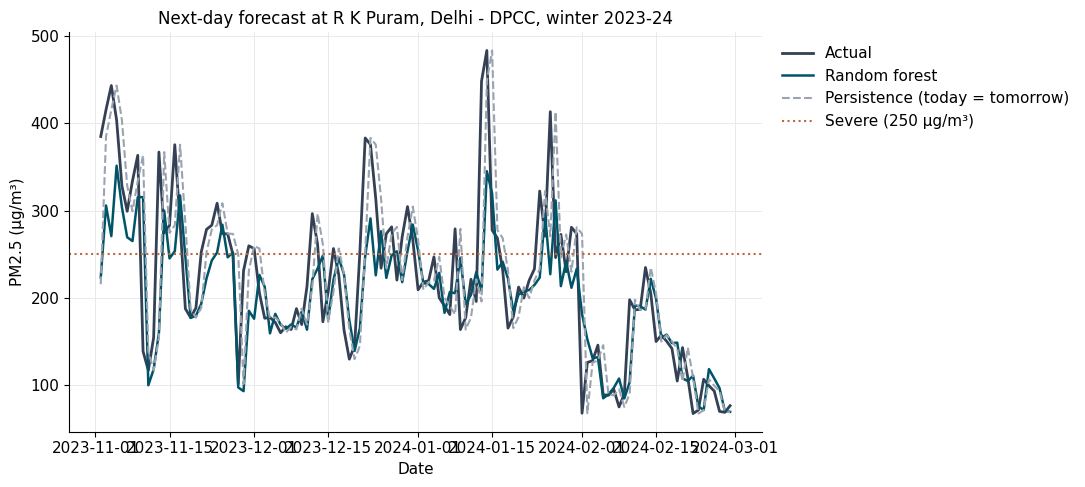

In [9]:
# Actual vs forecast for one Delhi station in winter 2023-24
delhitest = test[test['city'] == 'Delhi']
if len(delhitest) == 0:
    print('No Delhi station in the test set, so this figure is skipped.')
else:
    pick = delhitest['station'].value_counts().index[0]
    one = test[(test['station'] == pick) & (test['date'] >= '2023-11-01') & (test['date'] <= '2024-02-28')]
    day = one['date'] + pd.Timedelta(days=1)   # the day being forecast

    fig, ax = plt.subplots(figsize=(11, 5))
    ax.plot(day, one['pmnext'], color=slate, linewidth=2, label='Actual')
    ax.plot(day, one['rf'], color=teal, linewidth=1.8, label='Random forest')
    ax.plot(day, one['persist'], color=grey, linewidth=1.5, linestyle='--', label='Persistence (today = tomorrow)')
    ax.axhline(severe, color=orange, linestyle=':', linewidth=1.5, label='Severe (250 µg/m³)')
    ax.set_xlabel('Date')
    ax.set_ylabel('PM2.5 (µg/m³)')
    ax.set_title('Next-day forecast at ' + pick + ', winter 2023-24')
    ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1))
    plt.tight_layout()
    plt.savefig(figdir + 'nb2-forecast-vs-actual.png', dpi=300, bbox_inches='tight')
    plt.show()

**Observation:** At R K Puram the random forest follows the shape of the actual line but cuts off the high peaks. Persistence is always one day late.

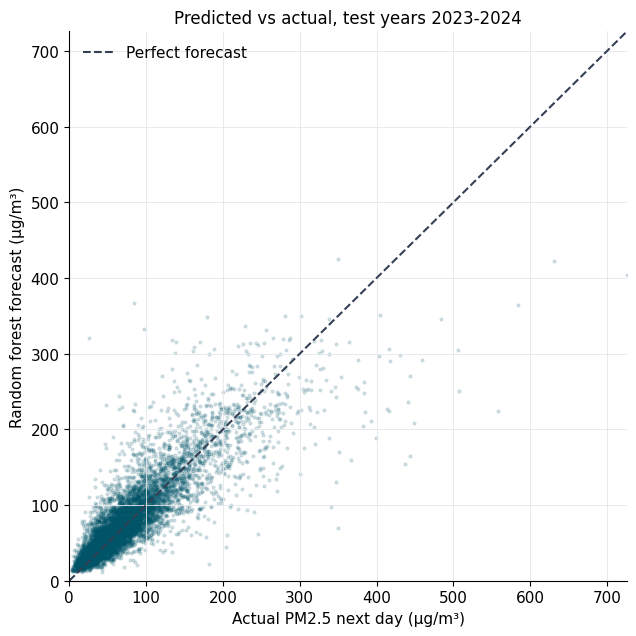

In [10]:
# Predicted vs actual for all test days, with a 45-degree line
fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.scatter(test['pmnext'], test['rf'], s=4, alpha=0.15, color=teal)
top = max(test['pmnext'].max(), test['rf'].max())
ax.plot([0, top], [0, top], color=slate, linewidth=1.5, linestyle='--', label='Perfect forecast')
ax.set_xlim(0, top)
ax.set_ylim(0, top)
ax.set_xlabel('Actual PM2.5 next day (µg/m³)')
ax.set_ylabel('Random forest forecast (µg/m³)')
ax.set_title('Predicted vs actual, test years 2023-2024')
ax.legend(loc='upper left')
plt.tight_layout()
plt.savefig(figdir + 'nb2-predicted-vs-actual.png', dpi=300, bbox_inches='tight')
plt.show()

**Observation:** The forecasts are good for normal days, but they flatten above about 300 µg/m³. A random forest averages many trees, so it pulls extreme values towards the middle.

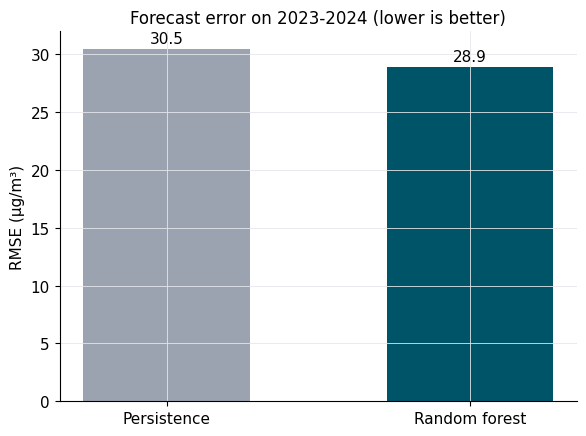

In [11]:
# Bar chart of RMSE: persistence vs random forest
fig, ax = plt.subplots(figsize=(6, 4.5))
bars = ax.bar(scores['model'], scores['rmse'], color=[grey, teal], width=0.55)
for bar in bars:
    ax.annotate(f'{bar.get_height():.1f}', (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                xytext=(0, 4), textcoords='offset points', ha='center')
ax.set_ylabel('RMSE (µg/m³)')
ax.set_title('Forecast error on 2023-2024 (lower is better)')
plt.tight_layout()
plt.savefig(figdir + 'nb2-rmse-bars.png', dpi=300, bbox_inches='tight')
plt.show()

**Observation:** The random forest bar (28.9) is only a little lower than the persistence bar (30.5), which is the 5% gain we saw in the table.

## Step 7: Which inputs matter most?
The random forest can tell us how much it used each input (feature importance). A higher bar means the input was used more.

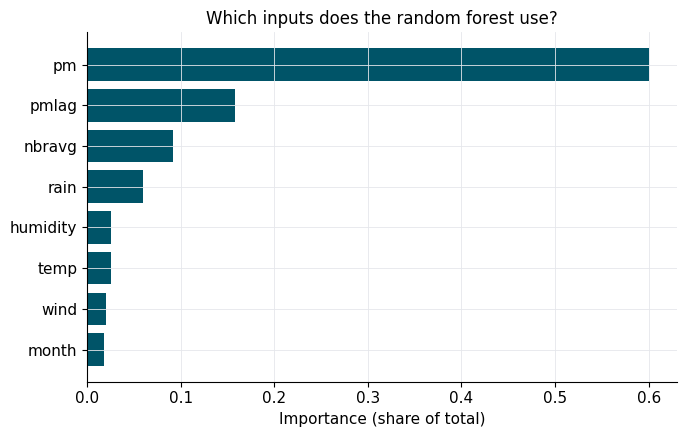

pm          0.600
pmlag       0.158
nbravg      0.092
rain        0.060
humidity    0.026
temp        0.025
wind        0.021
month       0.019
dtype: float32

In [12]:
# Feature importance of the Test 1 model, sorted
importance = pd.Series(model.feature_importances_, index=inputs).sort_values()
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(importance.index, importance.values, color=teal)
ax.set_xlabel('Importance (share of total)')
ax.set_title('Which inputs does the random forest use?')
plt.tight_layout()
plt.savefig(figdir + 'nb2-feature-importance.png', dpi=300, bbox_inches='tight')
plt.show()
importance.sort_values(ascending=False).round(3)

**Observation:** Today's PM2.5 is by far the most important input (about 0.6), then yesterday's PM2.5 (about 0.16), then the neighbour average (about 0.09) and rain. Temperature, humidity, wind and month matter little.

## Step 8: What is geography worth?
Now we train the same model on the same days but without the neighbour average. If the error goes up a lot, the neighbours really help the forecast.

Saved ../figures_outputs/nb2-ablation.csv
Value of geography (RMSE without - RMSE with): -0.05 µg/m³


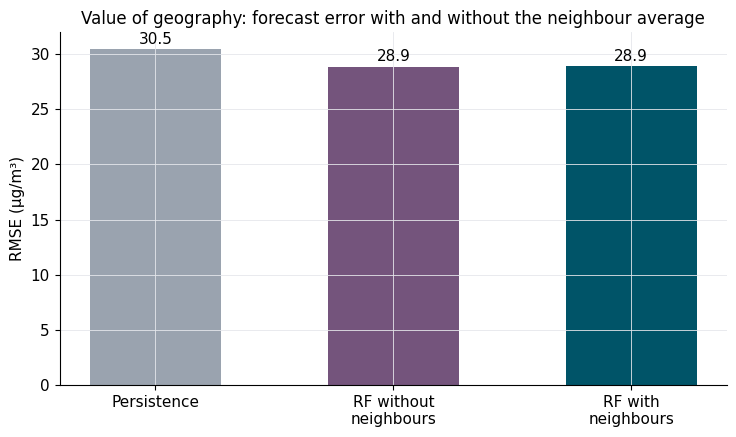

,setup,rmse,valueofgeography
0,Persistence,30.457,NaN
1,Random forest without nbravg,28.857,NaN
2,Random forest with nbravg,28.907,-0.05


In [13]:
# Train the same model without nbravg and compare the RMSE
without = list(inputs)
without.remove('nbravg')
model2 = makemodel()
model2.fit(train[without], train['pmnext'])
test['rfnogeo'] = model2.predict(test[without])

withgeo = rmse(test['pmnext'], test['rf'])
nogeo = rmse(test['pmnext'], test['rfnogeo'])
ablation = pd.DataFrame({
    'setup': ['Persistence', 'Random forest without nbravg', 'Random forest with nbravg'],
    'rmse': [rmse(test['pmnext'], test['persist']), nogeo, withgeo],
})
ablation['valueofgeography'] = [np.nan, np.nan, nogeo - withgeo]
savecsv(ablation.round(4), figdir + 'nb2-ablation.csv')
print('Value of geography (RMSE without - RMSE with):', round(nogeo - withgeo, 2), 'µg/m³')

fig, ax = plt.subplots(figsize=(7.5, 4.5))
bars = ax.bar(['Persistence', 'RF without\nneighbours', 'RF with\nneighbours'], ablation['rmse'],
              color=[grey, plum, teal], width=0.55)
for bar in bars:
    ax.annotate(f'{bar.get_height():.1f}', (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                xytext=(0, 4), textcoords='offset points', ha='center')
ax.set_ylabel('RMSE (µg/m³)')
ax.set_title('Value of geography: forecast error with and without the neighbour average')
plt.tight_layout()
plt.savefig(figdir + 'nb2-ablation.png', dpi=300, bbox_inches='tight')
plt.show()
ablation.round(3)

**Observation:** The RMSE is 28.9 with and without the neighbour average, so the neighbours add almost nothing. This matches Notebook 1: the cities move together on the same day, so today's neighbour value carries little extra information beyond the station's own value.

## Step 9: Test 2, forecasting a new city
Here we check if the model works on a city it has never seen. For each test city we train on all the other cities and test on this one. This is a smaller version of the "every city" test in our paper, to keep the notebook fast.

In [14]:
# Leave one city out: train on the other cities, test on this one
cityrows = []
for city in testcities:
    if city not in set(table['city']):
        print('Skipped', city, ': not in the data')
        continue
    trainc = table[table['city'] != city]
    testc = table[table['city'] == city]
    modelc = makemodel()
    modelc.fit(trainc[inputs], trainc['pmnext'])
    forecast = modelc.predict(testc[inputs])
    row = score(city, testc['pmnext'], forecast, testc['pm'])
    row['persistrmse'] = rmse(testc['pmnext'], testc['pm'])
    cityrows.append(row)
    print(city, ': skill =', round(row['skill'], 3), ' severe days =', row['severedays'])

citytable = pd.DataFrame(cityrows).rename(columns={'model': 'city'})
if len(citytable) > 0:
    savecsv(citytable.round(4), figdir + 'nb2-new-city-scores.csv')
citytable.round(3)

Delhi : skill = 0.085  severe days = 370
Kanpur : skill = 0.083  severe days = 116
Lucknow : skill = 0.108  severe days = 217
Skipped Varanasi : not in the data
Patna : skill = 0.081  severe days = 138
Saved ../figures_outputs/nb2-new-city-scores.csv


,city,rmse,skill,hitrate,falsealarm,days,severedays,persistrmse
0,Delhi,38.650,0.085,0.468,0.359,5618,370,42.223
1,Kanpur,28.998,0.083,0.483,0.356,2786,116,31.639
2,Lucknow,35.489,0.108,0.447,0.366,5241,217,39.774
3,Patna,29.967,0.081,0.370,0.329,2420,138,32.616


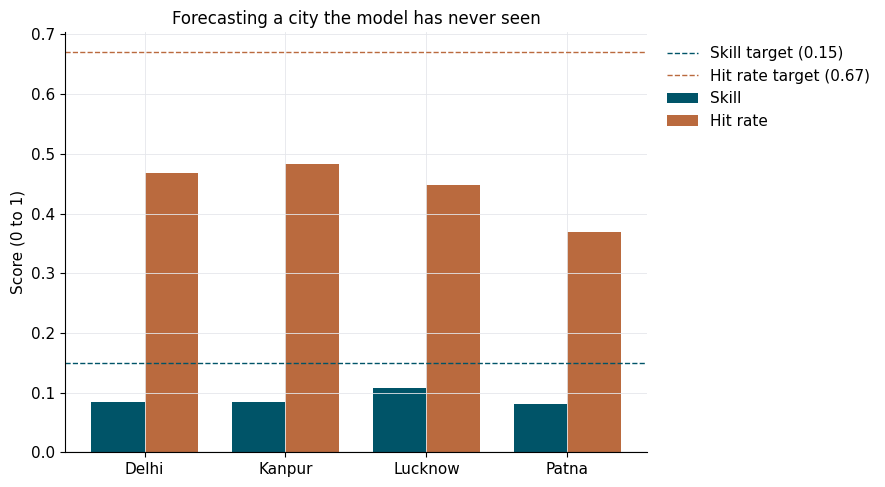

In [15]:
# Grouped bar chart of skill and hit rate per new city
if len(citytable) == 0:
    print('No test city found, nothing to plot.')
else:
    xs = np.arange(len(citytable))
    width = 0.38
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.bar(xs - width / 2, citytable['skill'], width, color=teal, label='Skill')
    ax.bar(xs + width / 2, citytable['hitrate'].fillna(0), width, color=orange, label='Hit rate')
    ax.axhline(0.15, color=teal, linestyle='--', linewidth=1, label='Skill target (0.15)')
    ax.axhline(0.67, color=orange, linestyle='--', linewidth=1, label='Hit rate target (0.67)')
    ax.axhline(0, color=slate, linewidth=0.8)
    ax.set_xticks(xs)
    ax.set_xticklabels(citytable['city'])
    ax.set_ylabel('Score (0 to 1)')
    ax.set_title('Forecasting a city the model has never seen')
    ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1))
    plt.tight_layout()
    plt.savefig(figdir + 'nb2-new-city-skill.png', dpi=300, bbox_inches='tight')
    plt.show()

**Observation:** The skill and hit rate are Delhi 0.08 / 0.47, Kanpur 0.08 / 0.48, Lucknow 0.11 / 0.45 and Patna 0.08 / 0.37. Skill on unseen cities is similar to or slightly better than on new years, so the model learned general patterns that transfer across places. Varanasi was skipped because it has no neighbour within 200 km, so it has no neighbour average.

## Step 10: Is the forecast useful?
We use the rule from our paper: the forecast is useful only if the skill is at least 0.15, the hit rate at least 0.67 and the false alarm rate at most 0.33.

In [16]:
# Apply the usefulness rule to Test 1 and to each city in Test 2
def useful(row):
    if np.isnan(row['hitrate']) or np.isnan(row['falsealarm']):
        return 'NO (hit rate or false alarm rate cannot be computed)'
    if row['skill'] >= 0.15 and row['hitrate'] >= 0.67 and row['falsealarm'] <= 0.33:
        return 'YES'
    return 'NO'


rfrow = scores[scores['model'] == 'Random forest'].iloc[0]
print('Test 1 (new years 2023-2024):', useful(rfrow))
for i in range(len(citytable)):
    row = citytable.iloc[i]
    print('Test 2, new city', row['city'], ':', useful(row))

Test 1 (new years 2023-2024): NO
Test 2, new city Delhi : NO
Test 2, new city Kanpur : NO
Test 2, new city Lucknow : NO
Test 2, new city Patna : NO


**Observation:** The answer is NO for Test 1 and NO for every city in Test 2. The model gives a small, steady gain over persistence, but it is not yet good enough for severe-day warnings.

## Summary
In this notebook we forecast next-day PM2.5 with a random forest and compared it with "tomorrow = today". The random forest is about 5% better on new years and about 8 to 11% better on new cities, so it learned general patterns, but it cuts off the high peaks and misses many severe days. Today's and yesterday's PM2.5 do most of the work, and the neighbour average adds almost nothing. So the answer to RQ1 is that a simple random forest gives a small, steady gain but is not yet useful for severe-day warnings. It could be improved with tomorrow's weather forecast as an input, a separate severe-day classifier, a boosted model and crop-fire counts.